<div dir="rtl" style="text-align:right;line-height:2.0;">
<h1>فاز دوم — گام چهارم: امید ریاضی، واریانس و کوواریانس</h1>
<p><strong>موضوع پژوهش:</strong> بررسی توزیع سطح ویتامین دی و همراهی آن با شاخص توده بدنی در بزرگسالان هجده‌ساله و بالاتر.</p>
<p>این نوت‌بوک به‌صورت مستقل از نوت‌بوک‌های پیشین اجرا می‌شود، اما دادهٔ اصلی را دقیقاً از خروجی ادغام‌شدهٔ فاز اول دریافت می‌کند. هیچ فایلی از نو ادغام یا دانلود نمی‌شود.</p>
<p>این گام دو وظیفهٔ رسمی فاز دوم را پوشش می‌دهد: تفسیر امید ریاضی و واریانس یک متغیر کمی، و بررسی نمودار پراکنش و کوواریانس دو متغیر کمی.</p>
<p>نام ستون‌های اصلی در فایل داده، به ترتیب سطح ویتامین دی، شاخص توده بدنی و وزن خون‌گیری:</p>
</div>

<div dir="ltr" style="text-align:left;">

`LBXVIDMS`

`BMXBMI`

`WTPH2YR_clean`

</div>

<div dir="rtl" style="text-align:right;line-height:2.0;">
<h2>۱. پرسش‌های آماری و واحد تحلیل</h2>
<p><strong>پرسش اول:</strong> سطح ویتامین دی در جامعهٔ مورد بررسی به‌طور متوسط چقدر است و چه میزان پراکندگی دارد؟</p>
<p><strong>پرسش دوم:</strong> آیا مقدار شاخص توده بدنی و سطح ویتامین دی در داده‌های مشاهده‌شده تمایل به تغییر هم‌جهت یا خلاف‌جهت دارند؟</p>
<p><strong>واحد مشاهده:</strong> یک فرد. ابتدا همان معیارهای مرحله‌های قبلی را برای دادهٔ ویتامین دی اعمال می‌کنیم؛ سپس برای محاسبهٔ کوواریانس فقط افراد دارای هر دو متغیر کمی را نگه می‌داریم. گمشدگی یکی از متغیرها نباید به عدد صفر تبدیل شود.</p>
<p>نتایج اصلی از وزن خون‌گیری استفاده می‌کنند. این وزن‌دهی برآوردهایی توصیفی از توزیعِ وزن‌دار به دست می‌دهد؛ واریانس محاسبه‌شده در اینجا واریانس مقادیر متغیر است، نه خطای استاندارد یا واریانس نمونه‌گیری برآوردگر تحت طرح پیچیدهٔ پیمایش.</p>
</div>

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Detect project root from GitHub clone or local working directory.
current = Path.cwd().resolve()
ancestors = [current, *current.parents[:2]]
project_root = next((p for p in ancestors if (p / '.git').exists() or (p / 'PROJECT_CARD.md').exists()), current)

candidate_data_paths = [
    project_root / 'data' / 'final_data.csv',
    project_root / 'final_data.csv',
    project_root.parent / 'vitamin-d-project' / 'data' / 'final_data.csv',
    project_root.parent / 'vitamin-d-project' / 'final_data.csv',
    current / 'data' / 'final_data.csv',
    current.parent / 'data' / 'final_data.csv',
    current / 'final_data.csv',
    current.parent / 'final_data.csv',
    Path.home() / 'Documents' / 'vitamin-d-project' / 'data' / 'final_data.csv',
    Path.home() / 'Documents' / 'vitamin-d-project' / 'final_data.csv',
]
candidate_data_paths = list(dict.fromkeys(p.resolve() for p in candidate_data_paths))
data_path = next((p for p in candidate_data_paths if p.is_file()), None)
if data_path is None:
    checked = '\n'.join(str(p) for p in candidate_data_paths)
    raise FileNotFoundError('Phase 1 dataset final_data.csv not found. Searched:\n' + checked)

df = pd.read_csv(data_path, low_memory=False)
columns = ['SEQN','RIDAGEYR','RIAGENDR','LBXVIDMS','BMXBMI','WTPH2YR_clean']
missing = sorted(set(columns) - set(df.columns))
if missing:
    raise ValueError(f'Missing required Phase 1 columns: {missing}')
for column in columns:
    df[column] = pd.to_numeric(df[column], errors='coerce')

if df['SEQN'].isna().any() or df['SEQN'].duplicated().any():
    raise ValueError('Participant identifiers are missing or repeated.')

eligible = (
    df['RIDAGEYR'].ge(18) & df['RIAGENDR'].isin([1,2]) &
    np.isfinite(df['LBXVIDMS']) &
    np.isfinite(df['WTPH2YR_clean']) & df['WTPH2YR_clean'].gt(0)
)
vitamin = df.loc[eligible].copy()
pair = vitamin.loc[np.isfinite(vitamin['BMXBMI'])].copy()

# Audit against the Phase 1 dataset and the prior Phase 2 analyses.
assert len(df) == 6337, 'Unexpected number of rows in Phase 1 dataset.'
assert len(vitamin) == 5824, 'Vitamin D analysis set does not match previous stages.'
assert len(pair) == 5744, 'Complete-case count for vitamin D and BMI changed; investigate.'
assert vitamin['SEQN'].is_unique and pair['SEQN'].is_unique

fig_dir = project_root / 'figures' / 'phase2'
report_dir = project_root / 'reports' / 'phase2'
fig_dir.mkdir(parents=True, exist_ok=True)
report_dir.mkdir(parents=True, exist_ok=True)

audit = pd.DataFrame({
    'Population': ['Phase 1 adults', 'Valid vitamin D and positive weight', 'Valid vitamin D, BMI and positive weight',
                   'Vitamin D observations without BMI'],
    'n': [len(df), len(vitamin), len(pair), len(vitamin)-len(pair)]
})
display(audit)
print('منبع دادهٔ فاز اول:', data_path)
print('محل خروجی‌های تصویری:', fig_dir)
print('محل جدول‌های گزارش:', report_dir)

,Population,n
0,Phase 1 adults,6337
1,Valid vitamin D and positive weight,5824
2,"Valid vitamin D, BMI and positive weight",5744
3,Vitamin D observations without BMI,80


منبع دادهٔ فاز اول: /mnt/data/_step4_portable_test/vitamin-d-project/data/final_data.csv
محل خروجی‌های تصویری: /mnt/data/_step4_portable_test/vitamin-d-project-github/figures/phase2
محل جدول‌های گزارش: /mnt/data/_step4_portable_test/vitamin-d-project-github/reports/phase2


<div dir="rtl" style="text-align:right;line-height:2.0;">
<h2>۲. امید ریاضی و واریانس تجربیِ وزن‌دار</h2>
<p>امید ریاضی مقدار متوسط متغیر تصادفی را در یک جمعیت توصیف می‌کند. واریانس، میانگین مربع فاصلهٔ مقادیر از همین متوسط است. انحراف معیار با جذرگیری از واریانس به واحد اصلی اندازه‌گیری بازمی‌گردد.</p>
<p>در این پژوهش، متغیر تصادفی سطح ویتامین دی را با وزن‌های نمونه‌گیری توصیف می‌کنیم.</p>
</div>

$$\widehat{E}_w[D]=\frac{\sum_i w_i D_i}{\sum_i w_i}$$

$$\widehat{\mathrm{Var}}_w(D)=\frac{\sum_i w_i(D_i-\widehat{E}_w[D])^2}{\sum_i w_i}$$

$$\widehat{\mathrm{SD}}_w(D)=\sqrt{\widehat{\mathrm{Var}}_w(D)}$$

<div dir="rtl" style="text-align:right;line-height:2.0;">
<p><strong>توجه:</strong> در این تعریفِ واریانس توصیفی، مجموع وزن‌ها مخرج است. از فرمول تصحیح‌شدهٔ برآورد واریانس نمونه‌گیری استفاده نمی‌کنیم، زیرا آن موضوع مربوط به فاز استنباطی پروژه است.</p>
</div>

In [2]:
def descriptive_weighted_moments(values, weights):
    v = np.asarray(values, dtype=float)
    w = np.asarray(weights, dtype=float)
    assert len(v) == len(w) and len(v) > 1
    assert np.isfinite(v).all() and np.isfinite(w).all() and (w > 0).all()
    normalized = w / w.sum()
    mean = float(np.sum(normalized*v))
    variance = float(np.sum(normalized*(v-mean)**2))
    second_moment = float(np.sum(normalized*v*v))
    assert np.isclose(variance, second_moment-mean**2, rtol=1e-10)
    return {'mean':mean, 'variance':variance, 'sd':float(np.sqrt(variance)), 'second_moment':second_moment}

def descriptive_unweighted_moments(values):
    v = np.asarray(values,dtype=float)
    mean = float(np.mean(v))
    var = float(np.mean((v-mean)**2)) # ddof=0: empirical distribution variance
    return {'mean':mean, 'variance':var, 'sd':float(np.sqrt(var)), 'second_moment':float(np.mean(v*v))}

x_full = vitamin['LBXVIDMS'].to_numpy(float)
w_full = vitamin['WTPH2YR_clean'].to_numpy(float)
raw_full = descriptive_unweighted_moments(x_full)
weighted_full = descriptive_weighted_moments(x_full, w_full)

summary_full = pd.DataFrame([
    {'Statistic':'Sample size', 'Unweighted':len(x_full),'Weighted':len(x_full),'Unit':'participants'},
    {'Statistic':'Expectation / mean', 'Unweighted':raw_full['mean'],'Weighted':weighted_full['mean'],'Unit':'nmol/L'},
    {'Statistic':'Variance', 'Unweighted':raw_full['variance'],'Weighted':weighted_full['variance'],'Unit':'(nmol/L)^2'},
    {'Statistic':'Standard deviation', 'Unweighted':raw_full['sd'],'Weighted':weighted_full['sd'],'Unit':'nmol/L'},
    {'Statistic':'Second raw moment E[D^2]', 'Unweighted':raw_full['second_moment'],
     'Weighted':weighted_full['second_moment'],'Unit':'(nmol/L)^2'}
])
display(summary_full.round(4))
print('میانگین وزن‌دار ویتامین دی:',round(weighted_full['mean'],4))
print('واریانس توصیفی وزن‌دار:',round(weighted_full['variance'],4))
print('انحراف معیار توصیفی وزن‌دار:',round(weighted_full['sd'],4))

,Statistic,Unweighted,Weighted,Unit
0,Sample size,5824.0000,5824.0000,participants
1,Expectation / mean,80.9197,78.1924,nmol/L
2,Variance,1435.3254,1280.3462,(nmol/L)^2
3,Standard deviation,37.8857,35.7819,nmol/L
4,Second raw moment E[D^2],7983.3259,7394.4046,(nmol/L)^2


میانگین وزن‌دار ویتامین دی: 78.1924
واریانس توصیفی وزن‌دار: 1280.3462
انحراف معیار توصیفی وزن‌دار: 35.7819


<div dir="rtl" style="text-align:right;line-height:2.0;">
<h2>۳. محاسبهٔ کوواریانس برای دو متغیر کمی</h2>
<p>برای محاسبهٔ کوواریانس، ابتدا باید هر دو متغیر را روی <strong>دقیقاً یک مجموعه از افراد</strong> داشته باشیم. به‌دلیل گمشده‌بودن شاخص توده بدنی برای بعضی افراد، تعداد مشاهده‌ها در این بخش کمتر از تحلیل تک‌متغیره است.</p>
<p>کوواریانس از میانگینِ حاصل‌ضرب انحراف‌های دو متغیر از میانگین‌های خودشان به دست می‌آید. اگر غالباً مقادیر بزرگ یکی با مقادیر کوچک دیگری همراه شوند، کوواریانس منفی خواهد بود.</p>
</div>

$$\widehat{\mathrm{Cov}}_w(D,B)=\frac{\sum_i w_i(D_i-\overline D_w)(B_i-\overline B_w)}{\sum_i w_i}$$

$$\widehat{\mathrm{Cov}}_w(D,B)=\widehat E_w[DB]-\widehat E_w[D]\widehat E_w[B]$$

<div dir="rtl" style="text-align:right;line-height:2.0;">
<p>واحد کوواریانس، حاصل‌ضرب واحدهای دو متغیر است؛ بنابراین اندازهٔ عدد کوواریانس به واحدهای اندازه‌گیری وابسته است و تنها از روی علامت آن می‌توان جهت همراهی خطی را توصیف کرد. از این عدد نباید رابطهٔ علّی یا معنی‌داری آماری نتیجه گرفت.</p>
</div>

In [3]:
d = pair['LBXVIDMS'].to_numpy(float)
b = pair['BMXBMI'].to_numpy(float)
w = pair['WTPH2YR_clean'].to_numpy(float)
wn = w / w.sum()

m_d = descriptive_weighted_moments(d,w)
m_b = descriptive_weighted_moments(b,w)
mean_d, mean_b = m_d['mean'],m_b['mean']
cov_w = float(np.sum(wn*(d-mean_d)*(b-mean_b)))
cov_w_identity = float(np.sum(wn*d*b) - mean_d*mean_b)
assert np.isclose(cov_w,cov_w_identity,rtol=1e-10,atol=1e-8)

raw_d = descriptive_unweighted_moments(d)
raw_b = descriptive_unweighted_moments(b)
cov_raw = float(np.mean((d-raw_d['mean'])*(b-raw_b['mean'])))

comparison = pd.DataFrame([
    {'Indicator':'Participants with both measures', 'Unweighted':len(pair),'Weighted':len(pair),'Unit':'people'},
    {'Indicator':'Mean vitamin D', 'Unweighted':raw_d['mean'], 'Weighted':m_d['mean'], 'Unit':'nmol/L'},
    {'Indicator':'Variance vitamin D','Unweighted':raw_d['variance'],'Weighted':m_d['variance'],'Unit':'(nmol/L)^2'},
    {'Indicator':'Mean BMI', 'Unweighted':raw_b['mean'],'Weighted':m_b['mean'],'Unit':'kg/m^2'},
    {'Indicator':'Variance BMI','Unweighted':raw_b['variance'],'Weighted':m_b['variance'],'Unit':'(kg/m^2)^2'},
    {'Indicator':'Covariance (vitamin D, BMI)','Unweighted':cov_raw,'Weighted':cov_w,'Unit':'(nmol/L)*(kg/m^2)'},
])
display(comparison.round(4))
print('تعداد مشاهدات جفتی:',len(pair))
print('کوواریانس وزن‌دار:',round(cov_w,4))
print('کوواریانس بدون وزن:',round(cov_raw,4))
print('تأیید هویت کوواریانس:', bool(np.isclose(cov_w,cov_w_identity)))

,Indicator,Unweighted,Weighted,Unit
0,Participants with both measures,5744.0000,5744.0000,people
1,Mean vitamin D,80.9701,78.1521,nmol/L
2,Variance vitamin D,1436.7371,1279.2350,(nmol/L)^2
3,Mean BMI,29.6472,29.5438,kg/m^2
4,Variance BMI,53.1225,52.9047,(kg/m^2)^2
5,"Covariance (vitamin D, BMI)",-30.3891,-32.1439,(nmol/L)*(kg/m^2)


تعداد مشاهدات جفتی: 5744
کوواریانس وزن‌دار: -32.1439
کوواریانس بدون وزن: -30.3891
تأیید هویت کوواریانس: True


<div dir="rtl" style="text-align:right;line-height:2.0;">
<h2>۴. نمودار پراکنش و جهت رابطه</h2>
<p>هر نقطه در نمودار زیر نشان‌دهندهٔ یک فرد است. خود نقطه‌ها صرفاً افراد مشاهده‌شده را نشان می‌دهند و اندازهٔ نقطه متناسب با وزن نمونه‌گیری نیست؛ خطوط نقطه‌چین، میانگین‌های <strong>وزن‌دار و مشترکِ همان افراد</strong> را مشخص می‌کنند.</p>
<p>تمام دامنهٔ هر دو متغیر را نمایش می‌دهیم تا نقاط انتهایی پنهان نشوند. نمودار به شناسایی جهت کلی همراهی کمک می‌کند، ولی برای برآورد رابطه علّی یا مقایسهٔ رسمی گروه‌ها کافی نیست.</p>
</div>

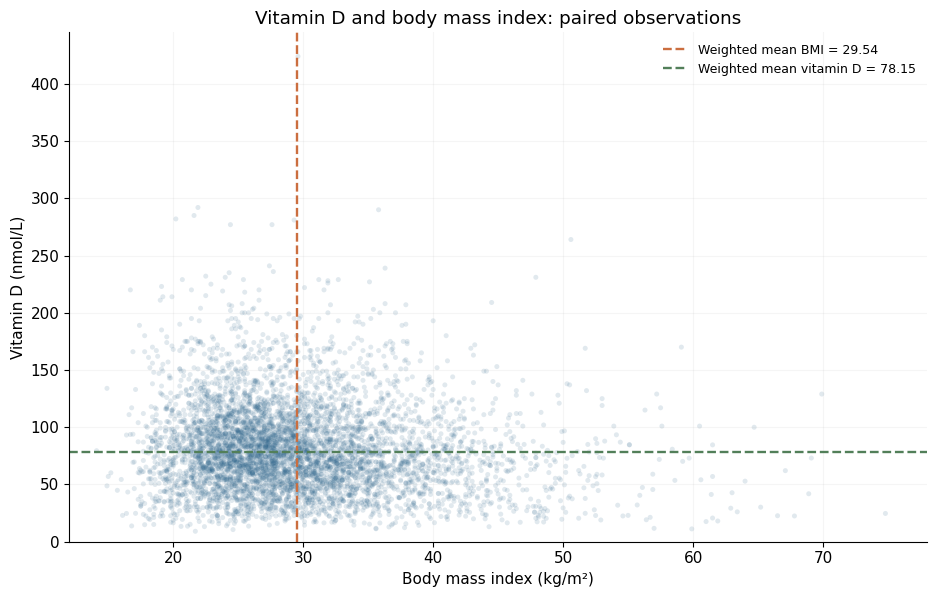

نمودار ذخیره شد: /mnt/data/_step4_portable_test/vitamin-d-project-github/figures/phase2/phase2_step4_vitamin_d_bmi_scatter.png


In [4]:
plt.rcParams.update({'font.size':11,'axes.spines.right':False,'axes.spines.top':False})
fig, ax=plt.subplots(figsize=(9.5,6.1))
ax.scatter(b,d,s=13,alpha=.14, color='#2C648B',edgecolors='none',rasterized=True)
ax.axvline(mean_b,color='#CB6E3F',ls='--',lw=1.7,label=f'Weighted mean BMI = {mean_b:.2f}')
ax.axhline(mean_d,color='#527F59',ls='--',lw=1.7,label=f'Weighted mean vitamin D = {mean_d:.2f}')
ax.set(xlabel='Body mass index (kg/m²)',ylabel='Vitamin D (nmol/L)',
       title='Vitamin D and body mass index: paired observations')
ax.set_xlim(12,78); ax.set_ylim(0,445)
ax.grid(alpha=.12)
ax.legend(frameon=False,fontsize=9,loc='upper right')
fig.tight_layout()
scatter_path=fig_dir/'phase2_step4_vitamin_d_bmi_scatter.png'
fig.savefig(scatter_path,dpi=180,bbox_inches='tight')
plt.show()
print('نمودار ذخیره شد:',scatter_path)

<div dir="rtl" style="text-align:right;line-height:2.0;">
<h2>۵. میانگین وزن‌دار ویتامین دی در بازه‌های شاخص توده بدنی</h2>
<p>برای خواناترشدن الگوی کلی در میان انبوه نقاط نمودار پراکنش، افراد را به هشت گروه تقریباً هم‌اندازه بر اساس شاخص توده بدنی تقسیم می‌کنیم. میانگین وزن‌دار ویتامین دی هر گروه محاسبه می‌شود.</p>
<p>این گروه‌بندی صرفاً توصیفی و اکتشافی است؛ نقطه‌های نمودار دوم مشاهدهٔ مستقلِ جدیدی نیستند و برای آن‌ها فاصلهٔ اطمینان یا آزمون فرض محاسبه نمی‌کنیم.</p>
</div>

,BMI interval,n,Weighted mean BMI,Weighted mean vitamin D,Unweighted mean vitamin D
0,"(14.099, 22.4]",731,20.448,80.223,83.401
1,"(22.4, 24.5]",710,23.577,84.276,85.564
2,"(24.5, 26.4]",721,25.492,81.535,83.795
3,"(26.4, 28.3]",727,27.360,79.997,82.991
4,"(28.3, 30.5]",725,29.419,78.913,81.328
5,"(30.5, 33.4]",707,31.947,76.748,80.451
6,"(33.4, 37.9]",712,35.387,75.638,79.756
7,"(37.9, 74.8]",711,43.862,67.381,70.319


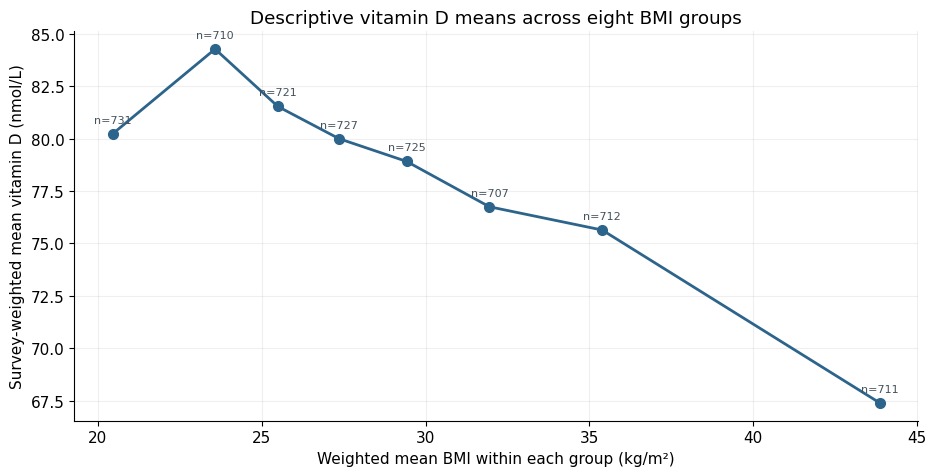

نمودار ذخیره شد: /mnt/data/_step4_portable_test/vitamin-d-project-github/figures/phase2/phase2_step4_weighted_bmi_group_profile.png


In [5]:
grouped = pair.copy()
grouped['bmi_group'] = pd.qcut(grouped['BMXBMI'], q=8, duplicates='drop')
rows=[]
for name, chunk in grouped.groupby('bmi_group', observed=True,sort=True):
    ww=chunk['WTPH2YR_clean'].to_numpy(float)
    rows.append({
        'BMI interval':str(name),
        'n':len(chunk),
        'Weighted mean BMI':float(np.average(chunk['BMXBMI'], weights=ww)),
        'Weighted mean vitamin D':float(np.average(chunk['LBXVIDMS'], weights=ww)),
        'Unweighted mean vitamin D':float(chunk['LBXVIDMS'].mean()),
    })
profile = pd.DataFrame(rows)
assert len(profile)==8 and profile['n'].sum()==len(pair)
display(profile.round(3))

fig,ax=plt.subplots(figsize=(9.5,4.9))
ax.plot(profile['Weighted mean BMI'],profile['Weighted mean vitamin D'],
        '-o',lw=2,color='#2C648B',markersize=7)
for _,item in profile.iterrows():
    ax.annotate(f"n={int(item['n'])}",
                (item['Weighted mean BMI'],item['Weighted mean vitamin D']),
                xytext=(0,8),textcoords='offset points',ha='center',fontsize=8,color='#43515B')
ax.set(xlabel='Weighted mean BMI within each group (kg/m²)',
       ylabel='Survey-weighted mean vitamin D (nmol/L)',
       title='Descriptive vitamin D means across eight BMI groups')
ax.grid(alpha=.2)
fig.tight_layout()
profile_path=fig_dir/'phase2_step4_weighted_bmi_group_profile.png'
fig.savefig(profile_path,dpi=180,bbox_inches='tight')
plt.show()
print('نمودار ذخیره شد:',profile_path)

<div dir="rtl" style="text-align:right;line-height:2.0;">
<h2>۶. پیوند با گام اول: امید و واریانس رویداد دودویی</h2>
<p>در گام اول رویداد «ویتامین دی کمتر از ۵۰» تعریف شد. اگر شاخص وقوع آن را متغیری با مقادیر صفر و یک در نظر بگیریم، میانگین وزن‌دار شاخص برابر همان احتمال تجربی وزن‌دار و واریانس آن از رابطهٔ زیر به دست می‌آید.</p>
</div>

$$E[I_A]=p,\qquad \mathrm{Var}(I_A)=p(1-p)$$

<div dir="rtl" style="text-align:right;line-height:2.0;">
<p>این هویت نشان می‌دهد که چگونه احتمال یک رویداد دودویی با امید ریاضی و واریانس متغیر تصادفی ارتباط پیدا می‌کند. برای سازگاری با محاسبات مرحله اول، این بخش را روی همان افراد دارای ویتامین دی معتبر محاسبه می‌کنیم.</p>
</div>

In [6]:
i_a = (x_full < 50.0).astype(float)
normalized_full=w_full / w_full.sum()
p = float(np.sum(normalized_full*i_a))
var_i = float(np.sum(normalized_full*(i_a-p)**2))
var_formula = p*(1-p)
assert np.isclose(var_i,var_formula,rtol=1e-12)
print(f'احتمال وزن‌دار رویداد: {p:.5f} (یعنی {100*p:.2f} درصد)')
print(f'واریانس متغیر صفر و یک: {var_i:.5f}')
print(f'مقدار حاصل از رابطهٔ احتمال: {var_formula:.5f}')

احتمال وزن‌دار رویداد: 0.20838 (یعنی 20.84 درصد)
واریانس متغیر صفر و یک: 0.16496
مقدار حاصل از رابطهٔ احتمال: 0.16496


<div dir="rtl" style="text-align:right;line-height:2.0;">
<h2>۷. کنترل کیفیت، ذخیره خروجی‌ها و تفسیر</h2>
<p>سه بررسی پیش از تحویل انجام می‌دهیم: شمارش و یکتایی افراد، هم‌ارزی دو فرمول واریانس و کوواریانس، و حفظ تفاوت بین جامعهٔ تک‌متغیره و جامعهٔ جفتی.</p>
<p><strong>تفسیر اصلی:</strong> مقدار منفی کوواریانس وزن‌دار نشان‌دهندهٔ همراهی خلاف‌جهت در توزیع تجربی است، نه شدت رابطه به‌صورت استاندارد، نه معنی‌داری آماری و نه اثر علّی شاخص توده بدنی بر ویتامین دی. تحلیل رگرسیون، همبستگی رسمی و استنباط پیچیده مربوط به فازهای بعدی پروژه است.</p>
<p><strong>محدودیت:</strong> صرف وزن‌دهی به میانگین‌ها، همبستگی درون خوشه‌های نمونه‌گیری و سایر ویژگی‌های طراحی پیمایش را برای استنباط پوشش نمی‌دهد. در این گام فقط خلاصه‌های توصیفی و احتمالات تجربی ارائه می‌کنیم.</p>
</div>

In [7]:
summary_full.to_csv(report_dir/'phase2_step4_vitamin_d_moments.csv',index=False,encoding='utf-8-sig')
comparison.to_csv(report_dir/'phase2_step4_bmi_covariance_summary.csv',index=False,encoding='utf-8-sig')
profile.to_csv(report_dir/'phase2_step4_bmi_group_means.csv',index=False,encoding='utf-8-sig')
audit.to_csv(report_dir/'phase2_step4_data_audit.csv',index=False,encoding='utf-8-sig')

print('--- Final checked values ---')
print(f'Vitamin D, n={len(vitamin)}: weighted mean={weighted_full["mean"]:.4f}, variance={weighted_full["variance"]:.4f}, SD={weighted_full["sd"]:.4f}')
print(f'Paired data, n={len(pair)}: weighted mean BMI={m_b["mean"]:.4f}, covariance={cov_w:.4f}')
print(f'Indicator E(I)={p:.5f}, Var(I)={var_i:.5f}')
print('Saved:',scatter_path.name,profile_path.name)
print('✓ Step 4 complete: descriptive moments and covariance.')

--- Final checked values ---
Vitamin D, n=5824: weighted mean=78.1924, variance=1280.3462, SD=35.7819
Paired data, n=5744: weighted mean BMI=29.5438, covariance=-32.1439
Indicator E(I)=0.20838, Var(I)=0.16496
Saved: phase2_step4_vitamin_d_bmi_scatter.png phase2_step4_weighted_bmi_group_profile.png
✓ Step 4 complete: descriptive moments and covariance.
